### 1. Project Title and Introduction

# Unemployment Analysis with Python

## Project Introduction

This project focuses on analyzing unemployment trends in India using Python.

The main objective is to explore unemployment patterns across different regions, understand monthly trends, compare major states, and analyze the impact of the COVID-19 period on unemployment.

## Objectives

1. Analyze unemployment rates across different regions.
2. Identify monthly unemployment trends.
3. Compare unemployment rates across major states.
4. Identify the top 10 regions with the highest average unemployment.
5. Analyze correlations between employment indicators.
6. Compare Pre-COVID and Post-COVID unemployment rates.

## Technologies Used

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

## Dataset

Dataset: Unemployment in India.csv

## 2. Import Libraries

In [1]:
# Import libraries required for data handling, numerical operations, and visualization.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

import warnings
warnings.filterwarnings("ignore")
print("Libraries Imported Successfully!")

Libraries Imported Successfully!


## 3. Data Loading

In [2]:
# Load the original unemployment dataset and inspect its basic structure.
df = pd.read_csv("Unemployment in India.csv")
print("Dataset Shape:", df.shape)
display(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())
print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Shape: (768, 7)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    str    
 1    Date                                     740 non-null    str    
 2    Frequency                                740 non-null    str    
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    str    
dtypes: float64(3), str(4)
memory usage: 66.1 KB

Missing Values:
Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unemployment Rate (%)       

## 4. Dataset Inspection

In [3]:
# Review dataset information, descriptive statistics, column names, and data types.
print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nDataset Columns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    str    
 1    Date                                     740 non-null    str    
 2    Frequency                                740 non-null    str    
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    str    
dtypes: float64(3), str(4)
memory usage: 66.1 KB

Statistical Summary:


,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740.000000,7.400000e+02,740.000000
mean,11.787946,7.204460e+06,42.630122
std,10.721298,8.087988e+06,8.111094
min,0.000000,4.942000e+04,13.330000
25%,4.657500,1.190404e+06,38.062500
50%,8.350000,4.744178e+06,41.160000
75%,15.887500,1.127549e+07,45.505000
max,76.740000,4.577751e+07,72.570000



Dataset Columns:
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']

Data Types:
Region                                          str
 Date                                           str
 Frequency                                      str
 Estimated Unemployment Rate (%)            float64
 Estimated Employed                         float64
 Estimated Labour Participation Rate (%)    float64
Area                                            str
dtype: object


## 5. Missing Values Check

Missing Values:
Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unemployment Rate (%)            28
 Estimated Employed                         28
 Estimated Labour Participation Rate (%)    28
Area                                        28
dtype: int64

Total Missing Values:
196

Duplicate Rows:
27


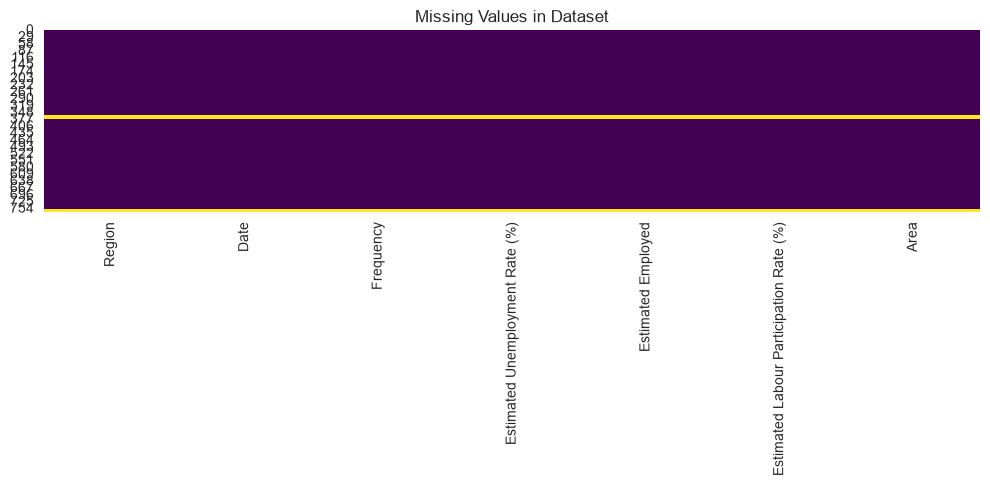

In [4]:
# Check missing values and duplicates, then visualize missing-value patterns.
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), cbar=False, cmap="viridis")
plt.title("Missing Values in Dataset")
plt.tight_layout()
plt.show()

## 6. Data Cleaning

In [5]:
# Clean column names and text values, convert data types, and remove invalid or duplicate rows.
df.columns = df.columns.astype(str).str.strip()

for column in df.select_dtypes(include="object").columns:
    df[column] = df[column].apply(lambda value: value.strip() if isinstance(value, str) else value)
df["Date"] = pd.to_datetime(df["Date"], errors="coerce", dayfirst=True)
numeric_columns = ["Estimated Unemployment Rate (%)", "Estimated Employed", "Estimated Labour Participation Rate (%)"]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")
required_columns = ["Region", "Date"] + numeric_columns

df = df.dropna(subset=required_columns)
df = df.drop_duplicates().copy()
df = df.sort_values("Date").reset_index(drop=True)

print("Data Cleaning Completed Successfully!")
print("\nCleaned Dataset Shape:", df.shape)

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())
print("\nDuplicate Rows After Cleaning:")
print(df.duplicated().sum())
display(df.head())

Data Cleaning Completed Successfully!

Cleaned Dataset Shape: (740, 7)

Missing Values After Cleaning:
Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Area                                       0
dtype: int64

Total Missing Values: 0

Duplicate Rows After Cleaning:
0


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Telangana,2019-05-31,Monthly,2.23,11053353.0,61.74,Rural
2,Tamil Nadu,2019-05-31,Monthly,0.97,15844698.0,49.44,Rural
3,Rajasthan,2019-05-31,Monthly,4.03,15226005.0,38.52,Rural
4,Punjab,2019-05-31,Monthly,9.17,6088547.0,44.79,Rural


### Markdown Observation 1 – Data Cleaning
- The original dataset contains blank or incomplete records.
- Column names and text values are standardized by removing extra spaces.
- The `Date` column is converted to datetime format.
- The unemployment rate, estimated employed count and labour participation rate are converted to numeric data types.
- Rows missing required analysis fields and duplicate rows are removed.
- A `Month` column is created for monthly trend analysis.

### 7. Feature Engineering

In [6]:
# Create a monthly time feature and derive an estimated employment-rate metric.
df["Month"] = df["Date"].dt.to_period("M").dt.to_timestamp()
df["Estimated Employment Rate (%)"] = (df["Estimated Labour Participation Rate (%)"] * (1 - df["Estimated Unemployment Rate (%)"] / 100))
print("Feature Engineering Completed!")

display(df[["Date", "Month", "Estimated Unemployment Rate (%)", "Estimated Labour Participation Rate (%)", "Estimated Employment Rate (%)"]].head())
print("\nUpdated Dataset Shape:", df.shape)
print("\nUpdated Columns:")
print(df.columns.tolist())

Feature Engineering Completed!


,Date,Month,Estimated Unemployment Rate (%),Estimated Labour Participation Rate (%),Estimated Employment Rate (%)
0,2019-05-31,2019-05-01,3.65,43.24,41.661740
1,2019-05-31,2019-05-01,2.23,61.74,60.363198
2,2019-05-31,2019-05-01,0.97,49.44,48.960432
3,2019-05-31,2019-05-01,4.03,38.52,36.967644
4,2019-05-31,2019-05-01,9.17,44.79,40.682757



Updated Dataset Shape: (740, 9)

Updated Columns:
['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area', 'Month', 'Estimated Employment Rate (%)']


## 8. Exploratory Data Analysis (EDA)

Number of Regions: 28
Date Range: 2019-05-31 00:00:00 to 2020-06-30 00:00:00


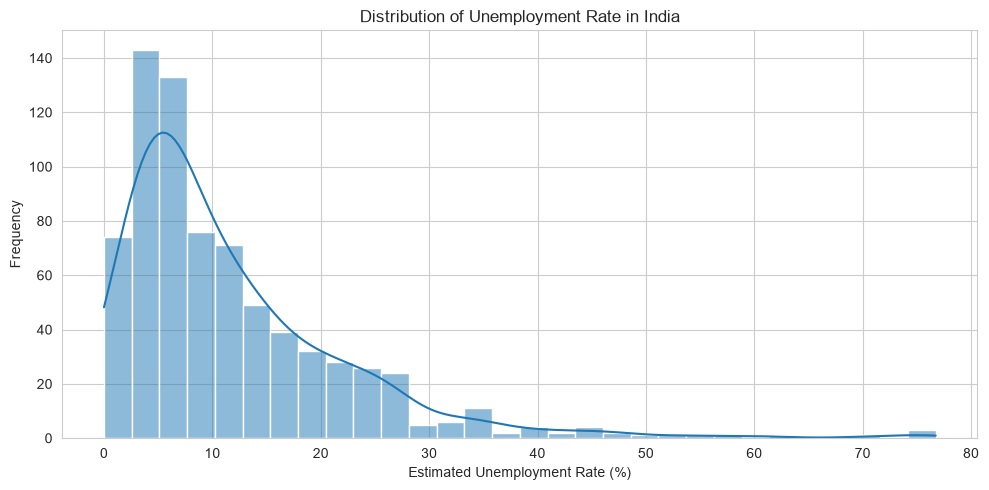

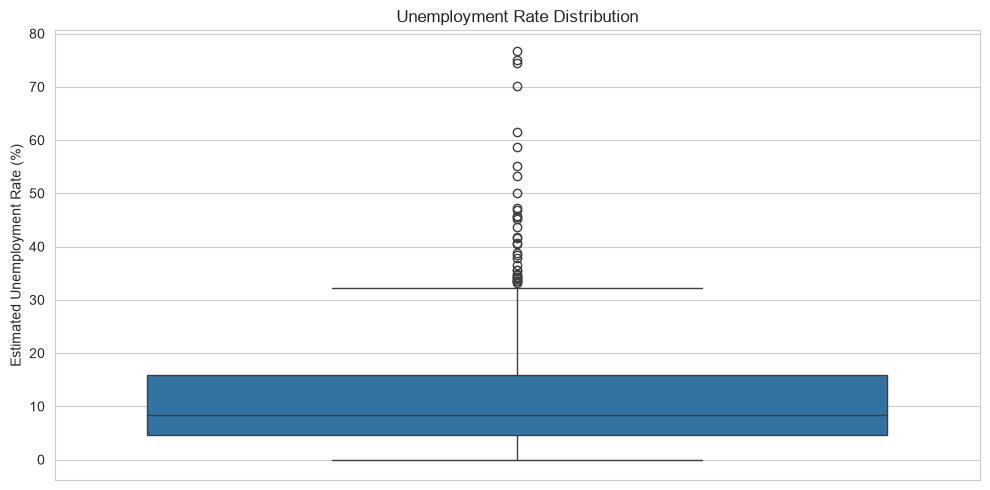

Overall Average Unemployment Rate: 11.79 %


In [7]:
# Explore the unemployment-rate distribution using summary statistics, a histogram, and a boxplot.
print("Number of Regions:", df["Region"].nunique())
print("Date Range:", df["Date"].min(), "to", df["Date"].max())

plt.figure(figsize=(10, 5))
sns.histplot(df["Estimated Unemployment Rate (%)"], bins=30, kde=True)
plt.title("Distribution of Unemployment Rate in India")
plt.xlabel("Estimated Unemployment Rate (%)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
sns.boxplot(y=df["Estimated Unemployment Rate (%)"])
plt.title("Unemployment Rate Distribution")
plt.ylabel("Estimated Unemployment Rate (%)")
plt.tight_layout()
plt.show()

print("Overall Average Unemployment Rate:", round(df["Estimated Unemployment Rate (%)"].mean(), 2), "%")

### Observation – Overall EDA

- The histogram shows the distribution of unemployment rates across the dataset.
- The distribution helps identify common unemployment rate ranges.
- The boxplot highlights the spread of unemployment rates and potential outliers.
- These visualizations provide an overview of unemployment patterns in India.

### 9. Region-wise Unemployment Analysis

Average Unemployment Rate by Region:


,Region,Estimated Unemployment Rate (%)
0,Tripura,28.350357
1,Haryana,26.283214
2,Jharkhand,20.585000
3,Bihar,18.918214
4,Himachal Pradesh,18.540357
5,Delhi,16.495357
6,Jammu & Kashmir,16.188571
7,Chandigarh,15.991667
8,Rajasthan,14.058214
9,Uttar Pradesh,12.551429


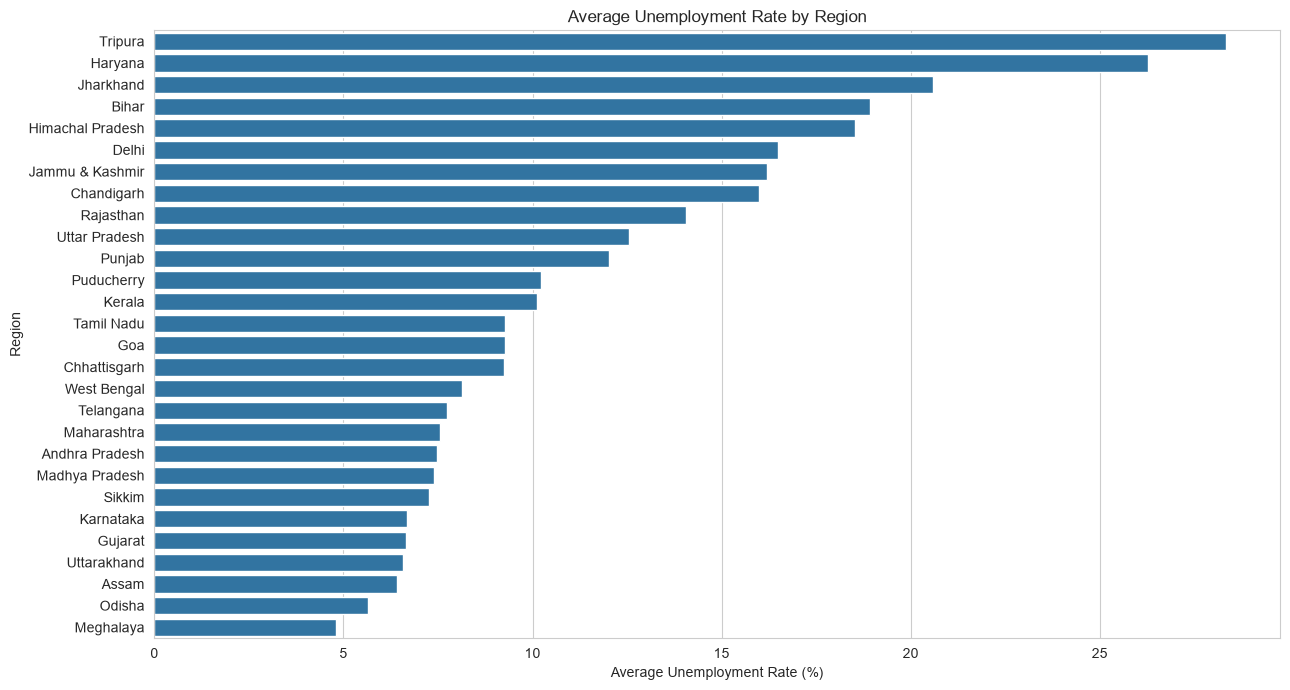

Highest average unemployment region: Tripura - 28.35 %
Lowest average unemployment region: Meghalaya - 4.8 %


In [8]:
# Calculate and visualize the average unemployment rate for each region.
region_unemployment = (df.groupby("Region")["Estimated Unemployment Rate (%)"].mean().sort_values(ascending=False))

print("Average Unemployment Rate by Region:")
display(region_unemployment.reset_index())

plt.figure(figsize=(13, 7))
sns.barplot(x=region_unemployment.values, y=region_unemployment.index)
plt.title("Average Unemployment Rate by Region")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

print("Highest average unemployment region:", region_unemployment.idxmax(), "-", round(region_unemployment.max(), 2), "%")
print("Lowest average unemployment region:", region_unemployment.idxmin(), "-", round(region_unemployment.min(), 2), "%")

### Observation – Region-wise Unemployment Analysis

- The bar chart compares average unemployment rates across different regions.
- Some regions have higher average unemployment rates than others.
- The analysis highlights regional variations in unemployment.
- These differences may be associated with regional economic and employment conditions.

## 10. Month-wise Unemployment Trend

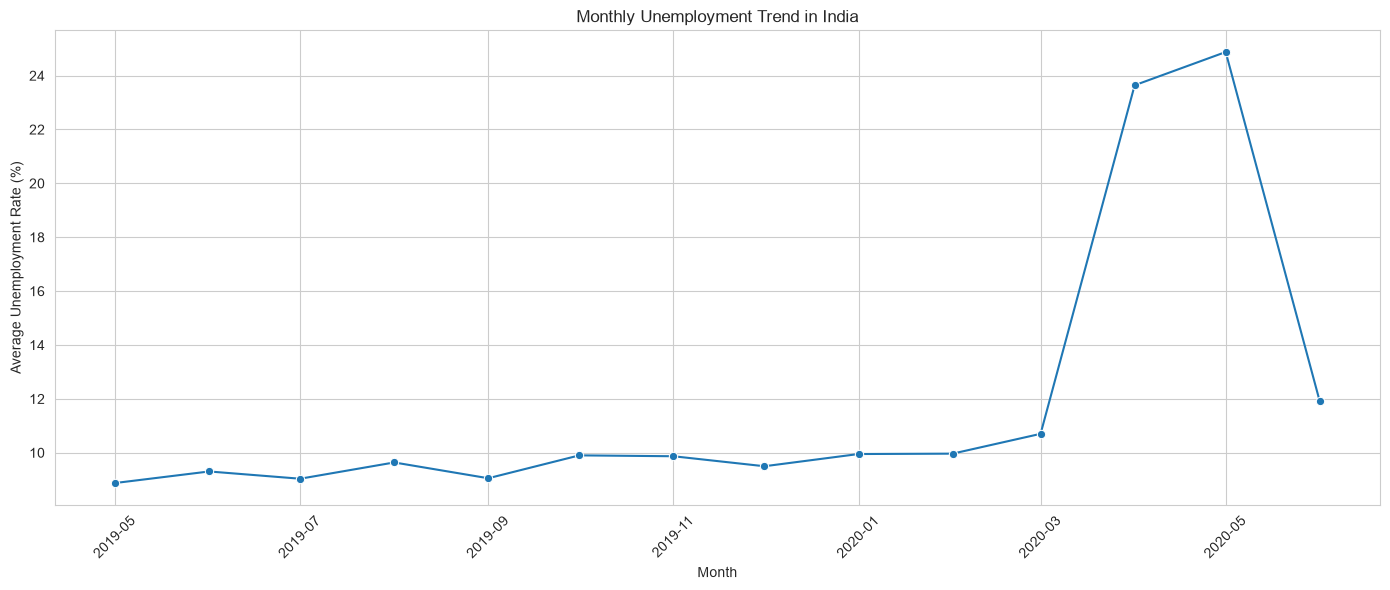

,Month,Estimated Unemployment Rate (%)
0,2019-05-01,8.874259
1,2019-06-01,9.303333
2,2019-07-01,9.033889
3,2019-08-01,9.637925
4,2019-09-01,9.051731
5,2019-10-01,9.900909
6,2019-11-01,9.868364
7,2019-12-01,9.497358
8,2020-01-01,9.950755
9,2020-02-01,9.964717


In [9]:
# Aggregate unemployment rates by month and plot the overall time-series trend.
monthly_unemployment = (df.groupby("Month")["Estimated Unemployment Rate (%)"].mean().reset_index())

plt.figure(figsize=(14, 6))
sns.lineplot(data=monthly_unemployment, x="Month", y="Estimated Unemployment Rate (%)", marker="o")
plt.title("Monthly Unemployment Trend in India")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(monthly_unemployment.head(10))

### Observation – Monthly Unemployment Trend

- The line chart shows how the average unemployment rate changes over time.
- Monthly fluctuations indicate variations in unemployment levels.
- Certain months show higher unemployment rates, while others show lower rates.
- The time-series analysis helps identify monthly patterns and changes.

## 11. State-wise Time Series Analysis

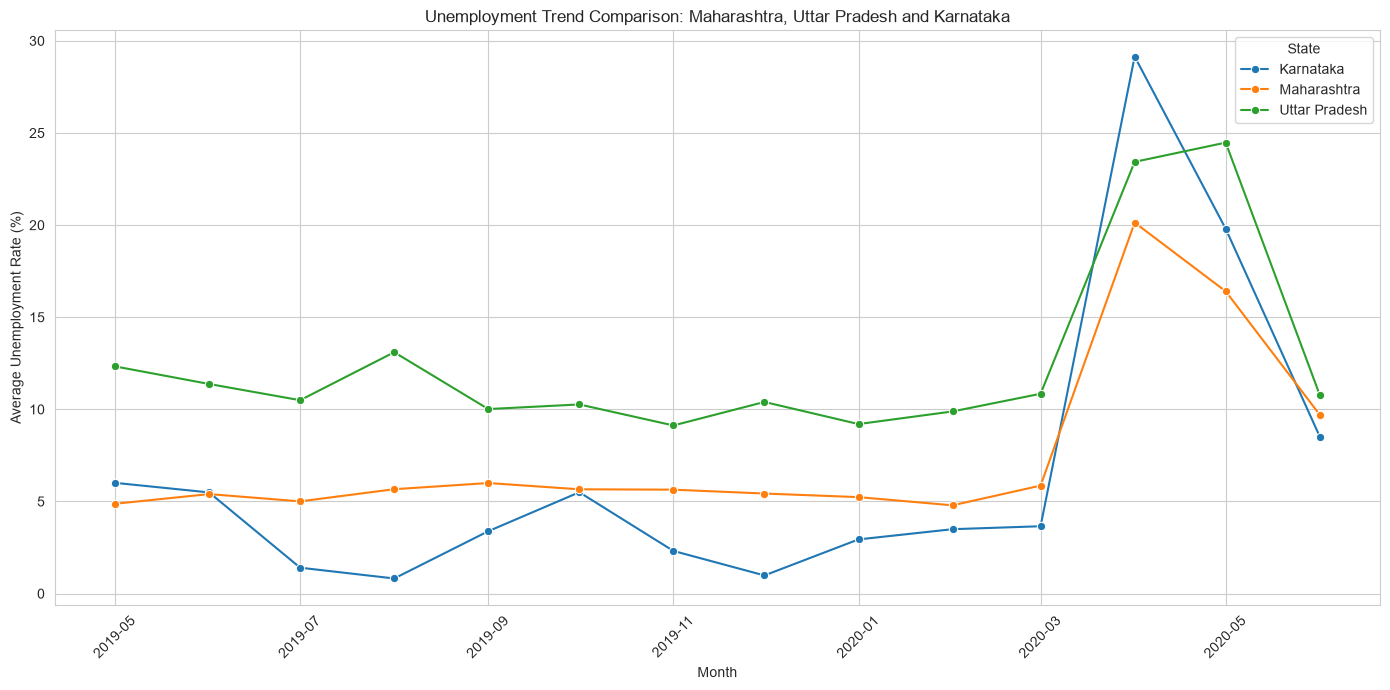

State-wise Average Unemployment:


,Region,Estimated Unemployment Rate (%)
0,Karnataka,6.68
1,Maharashtra,7.56
2,Uttar Pradesh,12.55


In [10]:
# Compare monthly unemployment trends for Maharashtra, Uttar Pradesh, and Karnataka.
selected_states = ["Maharashtra", "Uttar Pradesh", "Karnataka"]
state_data = df[df["Region"].isin(selected_states)].copy()
state_monthly = (state_data.groupby(["Month", "Region"])["Estimated Unemployment Rate (%)"].mean().reset_index())
plt.figure(figsize=(14, 7))
sns.lineplot(data=state_monthly, x="Month", y="Estimated Unemployment Rate (%)", hue="Region", marker="o")

plt.title("Unemployment Trend Comparison: Maharashtra, Uttar Pradesh and Karnataka")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.legend(title="State")
plt.tight_layout()
plt.show()

print("State-wise Average Unemployment:")
display(state_monthly.groupby("Region")["Estimated Unemployment Rate (%)"].mean().round(2).reset_index())

### Observation – State-wise Time Series Analysis

- The line chart compares unemployment trends in Maharashtra, Uttar Pradesh, and Karnataka.
- Each state shows different unemployment patterns over time.
- The unemployment rates fluctuate across different months.
- This comparison helps identify differences in employment trends among the selected states.

## 12. Top 10 Regions with Highest Average Unemployment

Top 10 Regions with Highest Average Unemployment:


,Region,Estimated Unemployment Rate (%)
0,Tripura,28.350357
1,Haryana,26.283214
2,Jharkhand,20.585000
3,Bihar,18.918214
4,Himachal Pradesh,18.540357
5,Delhi,16.495357
6,Jammu & Kashmir,16.188571
7,Chandigarh,15.991667
8,Rajasthan,14.058214
9,Uttar Pradesh,12.551429


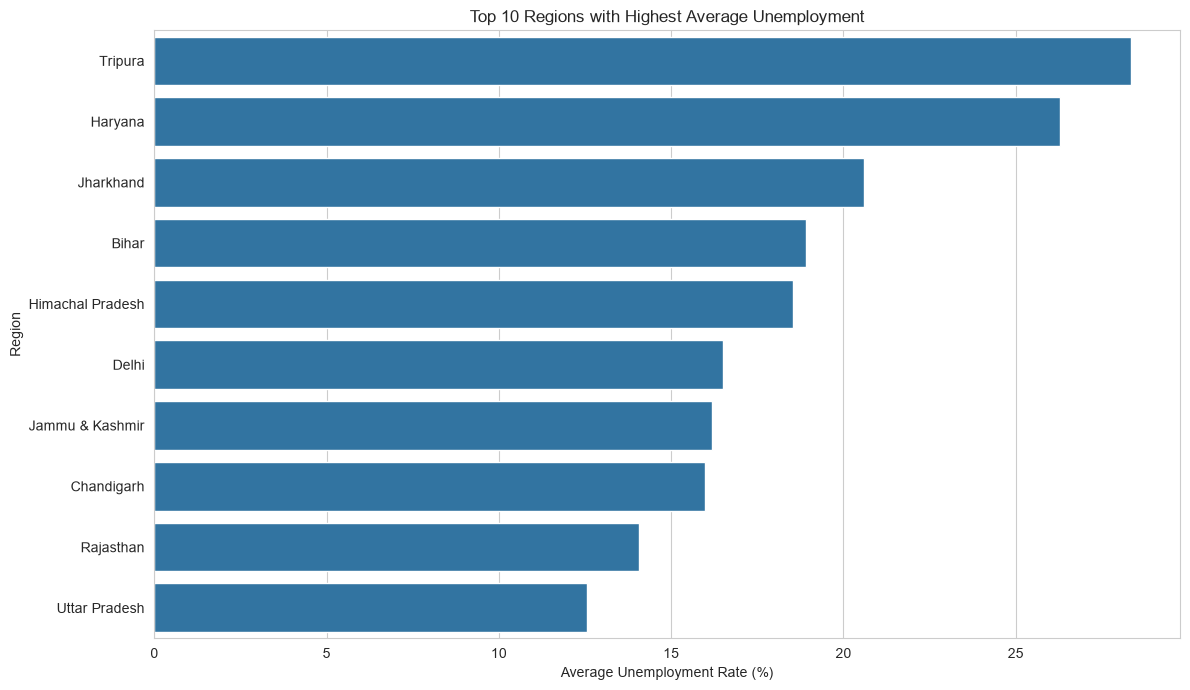

In [11]:
# Identify and visualize the ten regions with the highest average unemployment rates.
top_regions = (df.groupby("Region")["Estimated Unemployment Rate (%)"].mean().sort_values(ascending=False).head(10))

print("Top 10 Regions with Highest Average Unemployment:")
display(top_regions.reset_index())

plt.figure(figsize=(12, 7))
sns.barplot(x=top_regions.values, y=top_regions.index)

plt.title("Top 10 Regions with Highest Average Unemployment")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

### Observation – Top 10 Regions with Highest Average Unemployment

- The bar chart identifies the top 10 regions with the highest average unemployment rates.
- These regions have comparatively higher unemployment levels in the dataset.
- The ranking helps identify regions that may require greater attention.
- The results are based on average unemployment rates over the available observation period.

## 13. Correlation Heatmap

Correlation Matrix:


,Estimated Unemployment Rate (%),Estimated Employment Rate (%),Estimated Labour Participation Rate (%)
Estimated Unemployment Rate (%),1.000000,-0.541232,0.002558
Estimated Employment Rate (%),-0.541232,1.000000,0.829870
Estimated Labour Participation Rate (%),0.002558,0.829870,1.000000


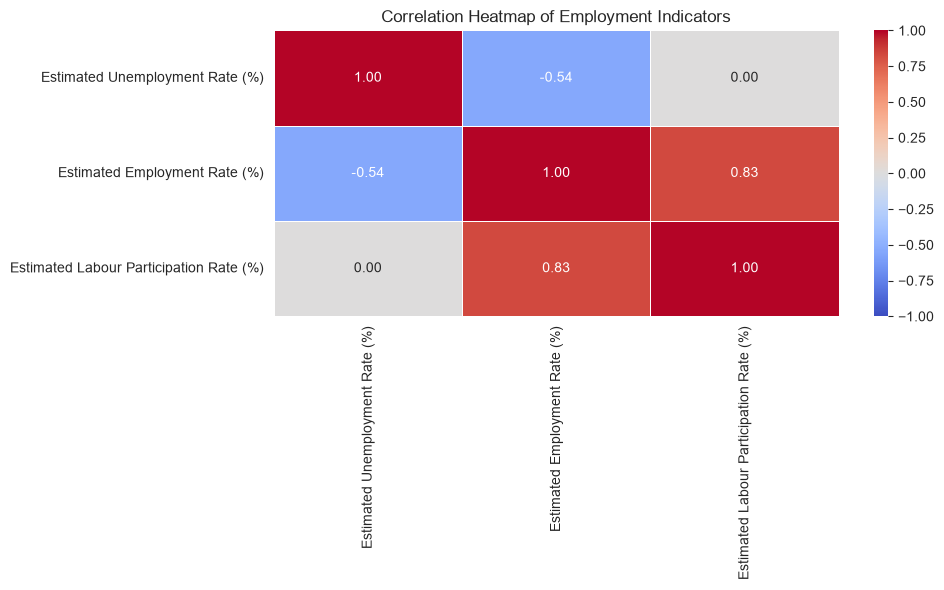

In [12]:
# Calculate correlations among unemployment, derived employment, and labour-participation rates.
correlation_columns = ["Estimated Unemployment Rate (%)", "Estimated Employment Rate (%)", "Estimated Labour Participation Rate (%)"]
correlation_matrix = df[correlation_columns].corr()

print("Correlation Matrix:")
display(correlation_matrix)
plt.figure(figsize=(10, 6))

sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title("Correlation Heatmap of Employment Indicators")
plt.tight_layout()
plt.show()

### Observation – Correlation Heatmap

- The heatmap represents the correlation between unemployment rate, estimated employment rate, and labour participation rate.
- Positive correlation indicates that two variables tend to move in the same direction.
- Negative correlation indicates that two variables tend to move in opposite directions.
- The strength of the relationship is represented by correlation values between -1 and +1.

**Note:** Estimated Employment Rate is a derived metric calculated using the unemployment rate and labour participation rate. Therefore, its correlations are partly influenced by the calculation formula and should not be interpreted as independent empirical relationships.

## 14. Pre-COVID vs Post-COVID Analysis

Pre-COVID vs Post-COVID Comparison:


,COVID Period,Average Unemployment Rate (%),Median Unemployment Rate (%),Number of Records
0,Post-COVID,17.77,14.52,204
1,Pre-COVID,9.51,7.12,536


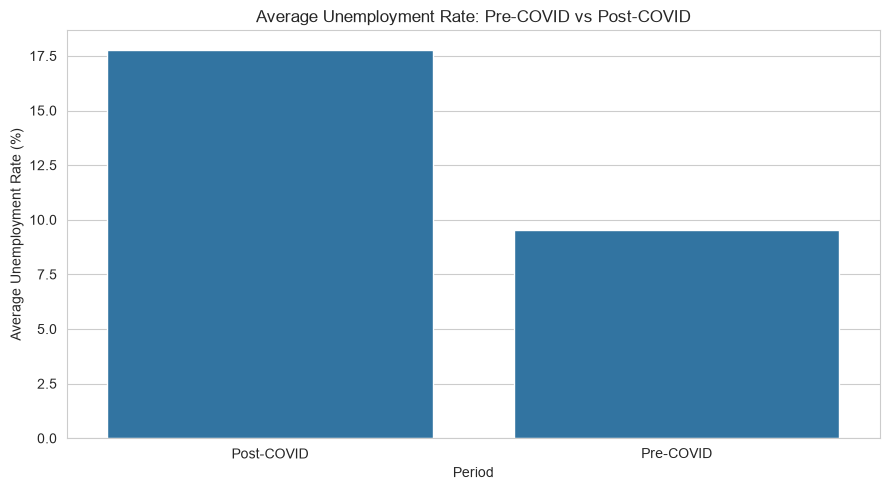

Pre-COVID Average: 9.51 %
Post-COVID Average: 17.77 %
Difference: 8.26 percentage points


In [13]:
# Divide records into Pre-COVID and Post-COVID periods and compare summary statistics.
covid_date = pd.Timestamp("2020-03-01")
df["COVID_Period"] = np.where(df["Date"] < covid_date, "Pre-COVID", "Post-COVID")

covid_comparison = (df.groupby("COVID_Period")["Estimated Unemployment Rate (%)"].agg(["mean", "median", "count"]).reset_index())
covid_comparison.columns = ["COVID Period", "Average Unemployment Rate (%)", "Median Unemployment Rate (%)", "Number of Records"]
print("Pre-COVID vs Post-COVID Comparison:")
display(covid_comparison.round(2))

plt.figure(figsize=(9, 5))
sns.barplot(data=covid_comparison, x="COVID Period", y="Average Unemployment Rate (%)")
plt.title("Average Unemployment Rate: Pre-COVID vs Post-COVID")
plt.xlabel("Period")
plt.ylabel("Average Unemployment Rate (%)")
plt.tight_layout()
plt.show()

period_averages = (df.groupby("COVID_Period")["Estimated Unemployment Rate (%)"].mean())
pre_covid_avg = period_averages.get("Pre-COVID", np.nan)
post_covid_avg = period_averages.get("Post-COVID", np.nan)
print("Pre-COVID Average:", round(pre_covid_avg, 2), "%")
print("Post-COVID Average:", round(post_covid_avg, 2), "%")
print("Difference:", round(post_covid_avg - pre_covid_avg, 2), "percentage points")

### Observation – Pre-COVID vs Post-COVID Analysis

- The bar chart compares average unemployment rates before and after March 2020.
- The comparison helps identify changes in unemployment levels across the two periods.
- The average unemployment rate may differ between the Pre-COVID and Post-COVID periods.
- This analysis provides a descriptive comparison of unemployment trends.

**Note:** The observed difference does not prove that COVID-19 alone caused the change in unemployment rates.

## 15. Key Observations and Conclusion

In [14]:
# Summarize the key findings and export the cleaned dataset for future use.
overall_avg = df["Estimated Unemployment Rate (%)"].mean()

highest_region = (df.groupby("Region")["Estimated Unemployment Rate (%)"].mean().idxmax())
highest_region_avg = (df.groupby("Region")["Estimated Unemployment Rate (%)"].mean().max())

lowest_region = (df.groupby("Region")["Estimated Unemployment Rate (%)"].mean().idxmin())
lowest_region_avg = (df.groupby("Region")["Estimated Unemployment Rate (%)"].mean().min())

highest_month = monthly_unemployment.loc[monthly_unemployment["Estimated Unemployment Rate (%)"].idxmax()]
lowest_month = monthly_unemployment.loc[monthly_unemployment["Estimated Unemployment Rate (%)"].idxmin()]

print("KEY OBSERVATIONS")
print("-" * 50)

print(f"1. Overall average unemployment rate: {overall_avg:.2f}%")
print(f"2. Highest average unemployment region: " f"{highest_region} ({highest_region_avg:.2f}%)")
print(f"3. Lowest average unemployment region: " f"{lowest_region} ({lowest_region_avg:.2f}%)")
print(f"4. Highest monthly average unemployment: " f"{highest_month['Month'].strftime('%B %Y')} " f"({highest_month['Estimated Unemployment Rate (%)']:.2f}%)")
print(f"5. Lowest monthly average unemployment: " f"{lowest_month['Month'].strftime('%B %Y')} " f"({lowest_month['Estimated Unemployment Rate (%)']:.2f}%)")

print("\nCONCLUSION")
print("-" * 50)

print("This project analyzed unemployment trends across different regions of India using Python.")
print("The analysis explored regional differences, monthly trends, state-wise comparisons, employment indicator correlations, and Pre-COVID vs Post-COVID patterns.")
print("The findings help understand changes in unemployment over time and differences between regions.")

df.to_csv("Unemployment_Cleaned.csv", index=False)
print("\nCleaned dataset exported successfully!")

KEY OBSERVATIONS
--------------------------------------------------
1. Overall average unemployment rate: 11.79%
2. Highest average unemployment region: Tripura (28.35%)
3. Lowest average unemployment region: Meghalaya (4.80%)
4. Highest monthly average unemployment: May 2020 (24.88%)
5. Lowest monthly average unemployment: May 2019 (8.87%)

CONCLUSION
--------------------------------------------------
This project analyzed unemployment trends across different regions of India using Python.
The analysis explored regional differences, monthly trends, state-wise comparisons, employment indicator correlations, and Pre-COVID vs Post-COVID patterns.
The findings help understand changes in unemployment over time and differences between regions.

Cleaned dataset exported successfully!


### Markdown Cell – Final Conclusion

# Final Conclusion

The Unemployment Analysis project successfully explored unemployment trends in India using Python libraries such as Pandas, NumPy, Matplotlib, and Seaborn.

The project identified regional variations, analyzed monthly unemployment patterns, compared selected states, and examined the differences between Pre-COVID and Post-COVID periods.

The correlation heatmap provided insights into relationships between employment indicators. The derived employment rate was interpreted carefully because it was calculated from existing variables.

Overall, this analysis demonstrates how data analysis and visualization can help identify unemployment patterns and support better understanding of employment trends in India.
